# dowload the region coeficients

In [13]:
import drms
client = drms.Client()

# Ver estructura de la serie
si = client.info('hmi.coefficients')
print(si.primekeys)   # te dice cuáles son las claves primarias reales
print(si.keywords.index.tolist())


['T_REC']
['T_REC', 'T_START', 'T_STOP', 'DATAUSED', 'CAL_FSN', 'DATE', 'NDATA', 'COEFF0', 'COEFF1', 'COEFF2', 'COEFF3']


In [14]:
query = client.query('hmi.coefficients[2017.08.03_TAI/8d]',key=si.keywords.index.tolist())
query

,T_REC,T_START,T_STOP,DATAUSED,CAL_FSN,DATE,NDATA,COEFF0,COEFF1,COEFF2,COEFF3
0,2017.08.03_06:45:00_TAI,2017.08.02_18:45:00_TAI,2017.08.03_18:45:00_TAI,hmi.V_45s_nrt[2017.08.02_18:45:00_TAI-2017.08....,121048472,2017-08-06T16:45:34Z,1881,188.0067,0.006999,-0.000007,-8.414051e-10
1,2017.08.03_18:45:00_TAI,2017.08.03_06:45:00_TAI,2017.08.04_06:45:00_TAI,hmi.V_45s_nrt[2017.08.03_06:45:00_TAI-2017.08....,121048472,2017-08-07T16:50:48Z,1887,187.5741,0.006670,-0.000007,-8.199870e-10
2,2017.08.04_06:45:00_TAI,2017.08.03_18:45:00_TAI,2017.08.04_18:45:00_TAI,hmi.V_45s_nrt[2017.08.03_18:45:00_TAI-2017.08....,121048472,2017-08-07T16:51:18Z,1921,187.2737,0.006637,-0.000007,-8.109732e-10
3,2017.08.04_18:45:00_TAI,2017.08.04_06:45:00_TAI,2017.08.05_06:45:00_TAI,hmi.V_45s_nrt[2017.08.04_06:45:00_TAI-2017.08....,121048472,2017-08-08T16:54:59Z,1921,187.5247,0.006753,-0.000007,-8.256654e-10
4,2017.08.05_06:45:00_TAI,2017.08.04_18:45:00_TAI,2017.08.05_18:45:00_TAI,hmi.V_45s_nrt[2017.08.04_18:45:00_TAI-2017.08....,121048472,2017-08-08T16:55:28Z,1921,187.4194,0.006948,-0.000007,-8.255739e-10
5,2017.08.05_18:45:00_TAI,2017.08.05_06:45:00_TAI,2017.08.06_06:45:00_TAI,hmi.V_45s_nrt[2017.08.05_06:45:00_TAI-2017.08....,121048472,2017-08-09T16:59:22Z,1920,187.1973,0.006837,-0.000007,-8.221256e-10
6,2017.08.06_06:45:00_TAI,2017.08.05_18:45:00_TAI,2017.08.06_18:45:00_TAI,hmi.V_45s_nrt[2017.08.05_18:45:00_TAI-2017.08....,121048472,2017-08-09T16:59:51Z,1919,187.4114,0.006596,-0.000007,-8.218669e-10
7,2017.08.06_18:45:00_TAI,2017.08.06_06:45:00_TAI,2017.08.07_06:45:00_TAI,hmi.V_45s_nrt[2017.08.06_06:45:00_TAI-2017.08....,121048472,2017-08-10T17:02:21Z,1920,188.3779,0.007331,-0.000007,-8.708458e-10
8,2017.08.07_06:45:00_TAI,2017.08.06_18:45:00_TAI,2017.08.07_18:45:00_TAI,hmi.V_45s_nrt[2017.08.06_18:45:00_TAI-2017.08....,121048472,2017-08-10T17:02:31Z,1921,189.6946,0.006326,-0.000007,-8.038637e-10
9,2017.08.07_18:45:00_TAI,2017.08.07_06:45:00_TAI,2017.08.08_06:45:00_TAI,hmi.V_45s_nrt[2017.08.07_06:45:00_TAI-2017.08....,121048472,2017-08-11T17:06:58Z,1921,190.8341,0.007165,-0.000006,-8.414437e-10


In [15]:
"""Inverting HMI's polynomial calibration, to rebuild a dopplergram from a raw cube.

Named `post_processing` because it undoes work JSOC already did: `hmi.coefficients` holds
the cubic that maps the instrument's measured quantity onto the published one, and
`invert_cubic` runs it backwards so the pre-calibration values can be recovered and a
different correction applied instead.

**Parked, not retired.** Nothing in the A or B line calls this. It is exercised only by
`01T_coefficient_reconstruction.ipynb` on the T line, kept because the option is wanted in
the pipeline eventually.

**The open caveat.** Reconstructing DS01's dopplergram this way does *not* reproduce the
shipped `cube_dopplergram_corrected.fits` — the correlation between the two is about zero.
The most likely reading is that the shipped file corrects something else (an orbital or
gravitational-redshift term) rather than the tuning nonlinearity this cubic describes. Until
that is settled, treat a reconstructed cube as an experiment, not as data.

A second reading, now that JSOC's series note is in hand: the cubic is a *correction* in m/s,
not a calibration curve mapping velocity to velocity, so `reconstruct_cubes` inverts the wrong
relation. `invert_hmi_correction` below solves the correction form instead.

Formulae, per frame:

    V = (V_lcp + V_rcp) / 2          B = (V_lcp - V_rcp) . K
"""

from __future__ import annotations

import numpy as np
import pandas as pd
from astropy.time import Time

K = 1.0 / (2.0 * 4.67e-5 * 0.000061733433 * 2.5 * 299792458.0)

_COEFF_KEYS = ['T_REC', 'T_START', 'T_STOP', 'COEFF0', 'COEFF1', 'COEFF2', 'COEFF3']


def fetch_coefficients(t_start: Time, t_stop: Time, pad_hours: float = 24.0) -> pd.DataFrame:
    """
    Fetch ``hmi.coefficients`` rows covering [t_start, t_stop], padded on
    each side so the very first/last cube frames still fall inside a
    matched [T_START, T_STOP) window.

    Returns a DataFrame with columns T_REC, T_START, T_STOP (as astropy
    Time-parsable strings converted to pandas Timestamps) and COEFF0..3,
    sorted by T_START.
    """
    import drms

    client = drms.Client()
    query_start = (t_start - pad_hours / 24.0).strftime('%Y.%m.%d_%H:%M:%S_TAI')
    span_days = (t_stop - t_start).jd + 2 * pad_hours / 24.0
    query = f'hmi.coefficients[{query_start}/{span_days:.3f}d]'
    df = client.query(query, key=_COEFF_KEYS)
    if df.empty:
        raise ValueError(f'No hmi.coefficients rows returned for query {query!r}')

    for col in ('T_REC', 'T_START', 'T_STOP'):
        df[col] = pd.to_datetime(
            df[col].str.replace('_TAI', '', regex=False).str.replace('.', '-', n=2, regex=False),
            format='%Y-%m-%d_%H:%M:%S',
        )
    return df.sort_values('T_START').reset_index(drop=True)


def match_coefficients_to_times(
    obs_times: Time, coeff_df: pd.DataFrame
) -> tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    """
    Match each frame's observation time to the hmi.coefficients row whose
    [T_START, T_STOP) window contains it.

    Parameters
    ----------
    obs_times : astropy.time.Time, shape (n_t,)
    coeff_df  : DataFrame from fetch_coefficients()

    Returns
    -------
    c0, c1, c2, c3 : np.ndarray, shape (n_t,)
    """
    frame_ts = pd.DataFrame({'t_obs': pd.to_datetime(obs_times.utc.datetime)}).sort_values('t_obs')

    matched = pd.merge_asof(
        frame_ts, coeff_df, left_on='t_obs', right_on='T_START', direction='backward',
    )
    # merge_asof requires sorted input; restore original frame order afterwards.
    matched = matched.sort_index()

    out_of_window = matched['t_obs'] >= matched['T_STOP']
    if out_of_window.any():
        raise ValueError(
            f'{out_of_window.sum()} frame(s) fall outside their matched '
            f'[T_START, T_STOP) coefficient window — widen pad_hours in fetch_coefficients().'
        )
    if matched['T_REC'].isna().any():
        raise ValueError('Some frames could not be matched to a coefficient row.')

    return (
        matched['COEFF0'].to_numpy(dtype=float),
        matched['COEFF1'].to_numpy(dtype=float),
        matched['COEFF2'].to_numpy(dtype=float),
        matched['COEFF3'].to_numpy(dtype=float),
    )


def _broadcast(c: np.ndarray, ndim: int = 3, dtype=np.float32) -> np.ndarray:
    """(n_t,) -> (n_t, 1, ..., 1), matching the rank of the data it multiplies.

    ``ndim`` and ``dtype`` come from the array being corrected: 3 for an (n_t, ny, nx) cube,
    1 for a plain (n_t,) time series such as a simulated velocity curve. Hard-
    coding (n_t, 1, 1) here used to blow up on the 1-D case — numpy refuses to
    broadcast a 3-D operand down onto a (n_t,) target.

    Rejects anything already shaped for broadcasting. Applying this twice gives
    (n_t, 1, 1, 1, 1), which right-aligns against an (n_t, ny, nx) cube into a
    frames x frames outer product — for a 480-frame 648x648 cube, 360 GiB. Numpy
    is happy to try, so the guard has to be here.

    ``dtype`` follows the data: float32 coefficients keep a float32 cube in
    float32, but a float64 series would otherwise be knocked back to ~1e-3 m/s
    of coefficient rounding — enough to speckle a metre-per-second difference
    between two inversions.
    """
    c = np.asarray(c, dtype=dtype)
    if c.ndim != 1:
        raise ValueError(
            f'coefficients must be 1-D (n_t,), got shape {c.shape}. '
            'apply_cubic/invert_cubic broadcast per-frame coefficients themselves — '
            'pass match_coefficients_to_times() output straight through.'
        )
    if ndim < 1:
        raise ValueError(f'data must have at least one axis, got ndim={ndim}')
    return c.reshape((-1,) + (1,) * (ndim - 1))


def apply_cubic(x: np.ndarray, c0: np.ndarray, c1: np.ndarray, c2: np.ndarray, c3: np.ndarray) -> np.ndarray:
    """
    Forward evaluation y = c0 + c1*x + c2*x**2 + c3*x**3, per-frame coefficients.

    x is expected in the same units as the raw dopplergram cubes (m/s). x may be
    an (n_t, ny, nx) cube or a plain (n_t,) series.
    """
    x = np.asarray(x)
    dtype = np.result_type(np.float32, x.dtype)
    c0, c1, c2, c3 = (_broadcast(c, x.ndim, dtype) for c in (c0, c1, c2, c3))
    return c0 + c1 * x + c2 * x**2 + c3 * x**3


def _cbrt(v: np.ndarray) -> np.ndarray:
    return np.sign(v) * np.abs(v) ** (1.0 / 3.0)


def invert_cubic(y: np.ndarray, c0: np.ndarray, c1: np.ndarray, c2: np.ndarray, c3: np.ndarray) -> np.ndarray:
    """
    Invert y = c0 + c1*x + c2*x**2 + c3*x**3 for x, vectorized over the whole
    cube via Cardano's formula on the depressed cubic.

    Per-frame coefficients (c0..c3, shape (n_t,)) are broadcast against y of
    shape (n_t, ny, nx) — or (n_t,) for a single time series. When the cubic
    has three real roots, the root
    closest to ``y`` itself is selected — a generic, assumption-free
    tie-breaker (no near-identity slope is assumed) that picks the
    physically plausible solution of the same order of magnitude as the
    measured value, rather than a wildly different root.
    """
    y = np.asarray(y)
    dtype = np.result_type(np.float32, y.dtype)
    a, b, c = c3, c2, c1
    a_b, b_b, c_b = (_broadcast(v, y.ndim, dtype) for v in (a, b, c))
    d_b = _broadcast(c0, y.ndim, dtype) - y

    p = (3 * a_b * c_b - b_b**2) / (3 * a_b**2)
    p = np.broadcast_to(p, y.shape)
    q = (2 * b_b**3 - 9 * a_b * b_b * c_b + 27 * a_b**2 * d_b) / (27 * a_b**3)

    disc = (q / 2) ** 2 + (p / 3) ** 3

    t = np.empty_like(y, dtype=float)

    one_real = disc > 0
    if np.any(one_real):
        sqrt_disc = np.sqrt(disc[one_real])
        u = _cbrt(-q[one_real] / 2 + sqrt_disc)
        v = _cbrt(-q[one_real] / 2 - sqrt_disc)
        t[one_real] = u + v

    three_real = ~one_real
    if np.any(three_real):
        p3 = p[three_real]
        q3 = q[three_real]
        r = 2 * np.sqrt(-p3 / 3)
        arg = np.clip((3 * q3) / (2 * p3) * np.sqrt(-3 / p3), -1.0, 1.0)
        theta = np.arccos(arg)
        candidates = np.stack(
            [r * np.cos((theta - 2 * np.pi * k) / 3) for k in range(3)], axis=0
        )
        # broadcast b/(3a) shift + pick root closest to y itself
        shift = (b_b / (3 * a_b))
        shift3 = np.broadcast_to(shift, y.shape)[three_real]
        x_candidates = candidates - shift3[None, ...]
        y3 = y[three_real]
        best = np.argmin(np.abs(x_candidates - y3[None, ...]), axis=0)
        t[three_real] = np.take_along_axis(candidates, best[None, ...], axis=0)[0]

    return t - b_b / (3 * a_b)


def apply_hmi_correction(x, c0, c1, c2, c3):
    """Apply HMI's Doppler velocity correction: v_corrected = x - poly(x).

    The forward direction of `invert_hmi_correction` — what the JSOC pipeline
    does to a measured velocity before publishing it.
    """
    x = np.asarray(x)
    return x - apply_cubic(x, c0, c1, c2, c3)


def invert_hmi_correction(y, c0, c1, c2, c3):
    """Recover the uncorrected velocity x from a corrected velocity y.

    JSOC describes hmi.coefficients as "the 4 polynomial coefficients for the
    3rd-order polynomial Doppler velocity correction": the cubic evaluates to a
    *correction* in m/s (about +188 m/s at v=0, staying inside +-200 m/s across
    the +-6 km/s tuning range), not to a velocity. The pipeline removes it,

        v_corrected = v_measured - poly(v_measured)

    so undoing it means solving x - poly(x) = y, which is the same cubic with
    coefficients (-c0, 1 - c1, -c2, -c3) — near-identity, so the recovered x
    sits within ~200 m/s of y instead of at the far root several km/s away that
    ``invert_cubic(y, c0, c1, c2, c3)`` lands on.
    """
    c0, c1, c2, c3 = (np.asarray(c, dtype=float) for c in (c0, c1, c2, c3))
    return invert_cubic(y, -c0, 1.0 - c1, -c2, -c3)


def vlcp_rcp_from_v_b(V: np.ndarray, B: np.ndarray, k: float = K) -> tuple[np.ndarray, np.ndarray]:
    """Given dopplergram V and magnetogram B, recover V_lcp, V_rcp."""
    V_lcp = V + B / (2.0 * k)
    V_rcp = V - B / (2.0 * k)
    return V_lcp, V_rcp


def v_b_from_vlcp_rcp(V_lcp: np.ndarray, V_rcp: np.ndarray, k: float = K) -> tuple[np.ndarray, np.ndarray]:
    """Given V_lcp, V_rcp, compute dopplergram V and magnetogram B."""
    V = (V_lcp + V_rcp) / 2.0
    B = (V_lcp - V_rcp) * k
    return V, B


def reconstruct_cubes(cube_dop, cube_mag, obs_times, k=K, pad_hours=24.0, chunk_frames=32, verbose=True):
    """Rebuild dopplergram and magnetogram cubes with HMI's cubic calibration inverted.

    Generalised from the loop that used to sit in `01B`: fetch the coefficients covering
    the observation window, match each frame to the 12 h window it falls in, split V and B
    into the two circular polarisations, invert the cubic on each, and recombine.

    Processed `chunk_frames` frames at a time (set to None to do the whole cube at once) —
    `invert_cubic` holds several full-size intermediates per call, so chunking bounds peak
    memory instead of scaling it with the whole cube.

    Returns `(cube_dop_reconstructed, cube_mag_reconstructed)`.
    """
    from astropy.time import Time

    times = Time(obs_times)
    coefficients = fetch_coefficients(times.min(), times.max(), pad_hours=pad_hours)
    c0, c1, c2, c3 = match_coefficients_to_times(times, coefficients)

    n_t = cube_dop.shape[0]
    dop = np.empty(cube_dop.shape, dtype=np.float32)
    mag = np.empty(cube_mag.shape, dtype=np.float32)

    step = n_t if chunk_frames is None else int(chunk_frames)
    for start in range(0, n_t, step):
        sl = slice(start, min(start + step, n_t))
        v_lcp, v_rcp = vlcp_rcp_from_v_b(cube_dop[sl], cube_mag[sl], k=k)
        v_lcp_raw = invert_cubic(v_lcp, c0[sl], c1[sl], c2[sl], c3[sl])
        v_rcp_raw = invert_cubic(v_rcp, c0[sl], c1[sl], c2[sl], c3[sl])
        dop[sl], mag[sl] = v_b_from_vlcp_rcp(v_lcp_raw, v_rcp_raw, k=k)

    if verbose:
        print(f'{n_t} frame(s) matched to {coefficients["T_REC"].nunique()} '
              f'coefficient window(s)')
    return dop, mag


def write_reconstructed_cube(cube, template_path, out_path, overwrite=False):
    """Write a reconstructed cube, reusing a template cube's header for its WCS."""
    import pathlib

    from astropy.io import fits

    out_path = pathlib.Path(out_path)
    if out_path.exists() and not overwrite:
        print(f'Skipping (already exists): {out_path}')
        return out_path
    with fits.open(template_path) as hdul:
        header = hdul[0].header.copy()
    fits.PrimaryHDU(np.asarray(cube, dtype=np.float32), header=header).writeto(
        out_path, overwrite=overwrite, output_verify='silentfix')
    print(f'Saved -> {out_path}')
    return out_path

In [16]:
from relative_velocity_sim import *

In [17]:
T_hours = 24 * 8
"""Plot relative velocity for a given phi, comparing different depths."""
t = np.linspace(0, T_hours * 3600, 5000)  # seconds
t_hours = t / 3600

In [18]:
t_hours%12

array([ 0.        ,  0.03840768,  0.07681536, ..., 11.92318464,
       11.96159232,  0.        ], shape=(5000,))

In [19]:
# hmi.coefficients ships a 24 h fit every 12 h, so the row in force at time t is
# the last one whose window has opened: 12 h bins counted from the first T_START.
# (Vectorised on purpose -- the old `for t in t_hours` loop rebound `t`, the
# seconds array every later cell depends on, and dropped the final sample.)
coeff = query[['COEFF0', 'COEFF1', 'COEFF2', 'COEFF3']].reset_index(drop=True)

BIN_HOURS = 12
row = np.clip((t_hours // BIN_HOURS).astype(int), 0, len(coeff) - 1)

coeff0, coeff1, coeff2, coeff3 = (coeff[c].to_numpy(dtype=float)[row] for c in coeff.columns)
coeffs = [coeff0, coeff1, coeff2, coeff3]

print(f'{len(t_hours)} samples matched to {len(np.unique(row))} of {len(coeff)} coefficient windows')

5000 samples matched to 16 of 16 coefficient windows


In [20]:
def relative_speed_with_polinomial(phi, t, coeffs, correction=True):
    """Simulated relative speed, run backwards through HMI's calibration.

    `correction=True` (default) undoes the Doppler velocity *correction* the HMI
    pipeline subtracts, i.e. solves x - poly(x) = v -- see `invert_hmi_correction`.
    `correction=False` treats the cubic as the calibration curve itself
    (y = poly(x)), which is what `reconstruct_cubes` does; over this velocity
    range that has no root anywhere near v.
    """
    v = relative_speed(phi, t)
    invert = invert_hmi_correction if correction else invert_cubic
    return invert(v, *coeffs)

## invert the HMI cubic on the simulated velocity

In [21]:
phi = 45

v_true = relative_speed(phi, t)                          # simulated LOS speed
v_corr = apply_hmi_correction(v_true, *coeffs)           # HMI's correction applied
v_raw = relative_speed_with_polinomial(phi, t, coeffs)   # correction undone

for name, v in [('simulated', v_true), ('corrected', v_corr), ('inverted ', v_raw)]:
    print(f'{name}  {v.min():9.2f} .. {v.max():9.2f} m/s   '
          f'(delta {np.min(v - v_true):+8.2f} .. {np.max(v - v_true):+8.2f})')

# the two directions must undo each other
print(f'round trip apply(invert(v)) - v : {np.abs(apply_hmi_correction(v_raw, *coeffs) - v_true).max():.3e} m/s')
print(f'round trip invert(apply(v)) - v : {np.abs(invert_hmi_correction(v_corr, *coeffs) - v_true).max():.3e} m/s')

simulated    1791.36 ..   4384.96 m/s   (delta    +0.00 ..    +0.00)
corrected    1617.55 ..   4363.00 m/s   (delta  -174.45 ..   -21.96)
inverted     1960.68 ..   4404.94 m/s   (delta   +19.98 ..  +169.92)
round trip apply(invert(v)) - v : 1.182e-11 m/s
round trip invert(apply(v)) - v : 1.091e-11 m/s


Saved -> /home/thomas/Projects/sun_rotacion_sim/relative_velocity_polynomial_inversion_phi45.png


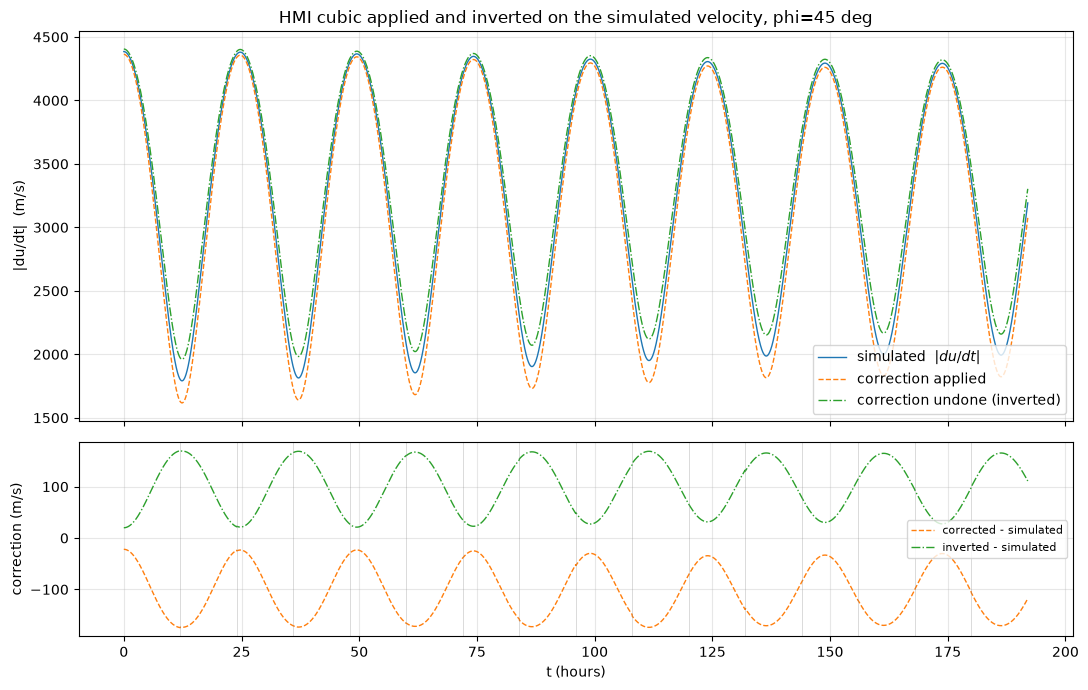

In [22]:
fig, (ax0, ax1) = plt.subplots(2, 1, figsize=(11, 7), sharex=True,
                               gridspec_kw={'height_ratios': [2, 1]})

ax0.plot(t_hours, v_true, lw=1.0, label='simulated  $|du/dt|$')
ax0.plot(t_hours, v_corr, lw=1.0, ls='--', label='correction applied')
ax0.plot(t_hours, v_raw, lw=1.0, ls='-.', label='correction undone (inverted)')
ax0.set_ylabel('|du/dt|  (m/s)')
ax0.set_title(f'HMI cubic applied and inverted on the simulated velocity, phi={phi} deg')
ax0.legend()
ax0.grid(True, alpha=0.3)

ax1.plot(t_hours, v_corr - v_true, lw=1.0, ls='--', color='tab:orange', label='corrected - simulated')
ax1.plot(t_hours, v_raw - v_true, lw=1.0, ls='-.', color='tab:green', label='inverted - simulated')
for edge in np.arange(BIN_HOURS, t_hours[-1], BIN_HOURS):   # coefficient-window boundaries
    ax1.axvline(edge, color='gray', lw=0.5, alpha=0.4)
ax1.set_xlabel('t (hours)')
ax1.set_ylabel('correction (m/s)')
ax1.legend(fontsize=8)
ax1.grid(True, alpha=0.3)

fig.tight_layout()
out_path = f'/home/thomas/Projects/sun_rotacion_sim/relative_velocity_polynomial_inversion_phi{phi}.png'
fig.savefig(out_path, dpi=150)
print(f'Saved -> {out_path}')

Saved -> /home/thomas/Projects/sun_rotacion_sim/depth_signal_polynomial_inversion_phi45.png
depth    200 km:  simulated +- 0.373   corrected +- 0.410   inverted +- 0.362  (m/s)
depth    600 km:  simulated +- 1.120   corrected +- 1.231   inverted +- 1.085  (m/s)
depth   1200 km:  simulated +- 2.240   corrected +- 2.461   inverted +- 2.169  (m/s)


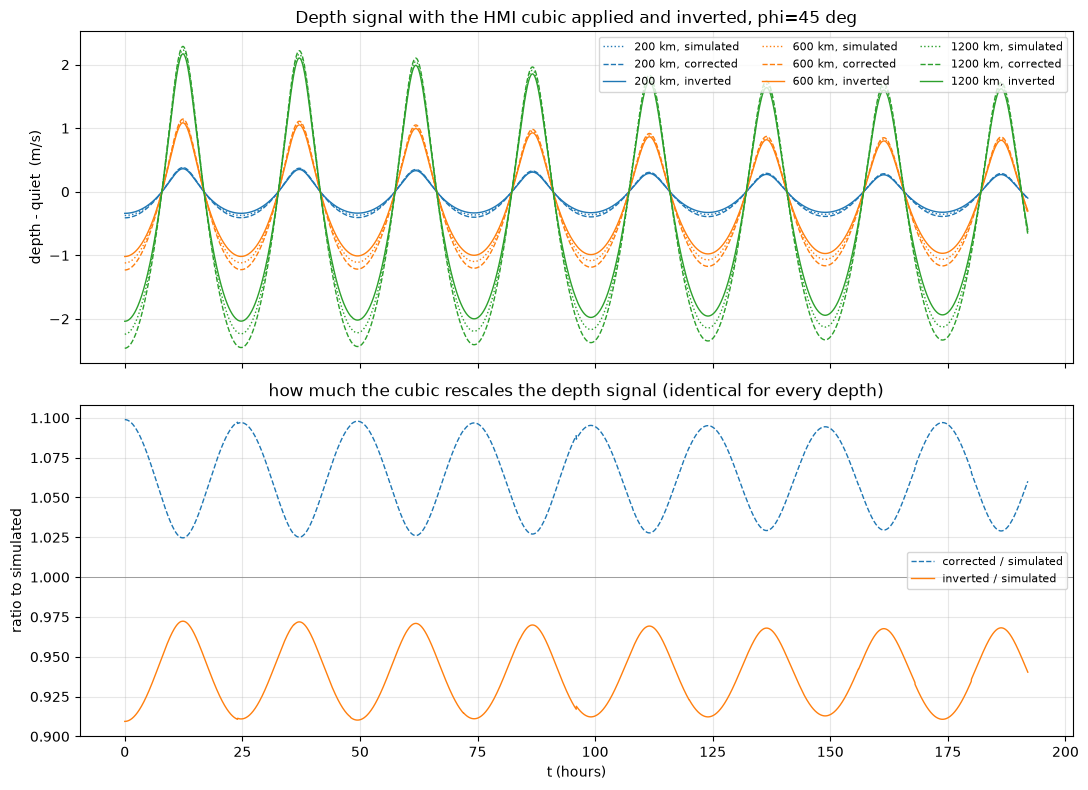

In [33]:
import relative_velocity_sim as rvs


def speed_at_depth(phi, t, depth):
    """relative_speed() with the emitting layer sunk `depth` metres below R_sun.

    relative_speed() reads R_sun from its own module, so the radius has to be
    rebound there — a `global R_sun` in a notebook cell only shadows it and every
    curve comes out identical.
    """
    R_sun_original = rvs.R_sun
    try:
        rvs.R_sun = R_sun_original - depth
        return relative_speed(phi, t)
    finally:
        rvs.R_sun = R_sun_original


# the three ways of reading the same simulated velocity
TRANSFORMS = {
    'simulated': lambda v: v,
    'corrected': lambda v: apply_hmi_correction(v, *coeffs),
    'inverted': lambda v: invert_hmi_correction(v, *coeffs),
}
STYLES = {'simulated': ':', 'corrected': '--', 'inverted': '-'}

phi = 45
depths = [200 * 1000, 600 * 1000, 1200 * 1000]  # depths in meters

v_quiet = speed_at_depth(phi, t, 0.0)                                  # quiet Sun, R_sun
quiet = {name: f(v_quiet) for name, f in TRANSFORMS.items()}
x_quiet = quiet['inverted']

fig, (ax0, ax1) = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

for depth in depths:
    v_depth = speed_at_depth(phi, t, depth)
    color = None
    for name, f in TRANSFORMS.items():
        diff = f(v_depth) - quiet[name]
        line, = ax0.plot(t_hours, diff, lw=1.0, ls=STYLES[name], color=color,
                         label=f'{depth / 1000:.0f} km, {name}')
        color = color or line.get_color()
        if depth == depths[0] and name != 'simulated':
            # the ratio is the local slope 1 -+ poly'(v); the same for every depth
            ax1.plot(t_hours, diff / (v_depth - v_quiet), lw=1.0, ls=STYLES[name],
                     label=f'{name} / simulated')

ax0.set_ylabel('depth - quiet  (m/s)')
ax0.set_title(f'Depth signal with the HMI cubic applied and inverted, phi={phi} deg')
ax0.legend(fontsize=8, ncol=3)
ax0.grid(True, alpha=0.3)

ax1.axhline(1.0, color='gray', lw=0.5)
ax1.set_xlabel('t (hours)')
ax1.set_ylabel('ratio to simulated')
ax1.set_title('how much the cubic rescales the depth signal (identical for every depth)')
ax1.legend(fontsize=8)
ax1.grid(True, alpha=0.3)

fig.tight_layout()
out_path = f'/home/thomas/Projects/sun_rotacion_sim/depth_signal_polynomial_inversion_phi{phi}.png'
fig.savefig(out_path, dpi=150)
print(f'Saved -> {out_path}')

for depth in depths:
    v_depth = speed_at_depth(phi, t, depth)
    cols = '   '.join(f'{name} +-{np.abs(f(v_depth) - quiet[name]).max():6.3f}'
                      for name, f in TRANSFORMS.items())
    print(f'depth {depth / 1000:6.0f} km:  {cols}  (m/s)')

## depression vs amplitude of the differential velocity

Saved -> /home/thomas/Projects/sun_rotacion_sim/depth_vs_amplitude_phi45.png
simulated: 1.8630 (m/s) per 1000 km  ->   536.77 km per (m/s)   [ +0.0% vs simulated]
corrected: 1.9782 (m/s) per 1000 km  ->   505.50 km per (m/s)   [ -5.8% vs simulated]
 inverted: 1.7527 (m/s) per 1000 km  ->   570.54 km per (m/s)   [ +6.3% vs simulated]
linearity: max |depth - k*amp| = 1.921 m over 0..2000 km


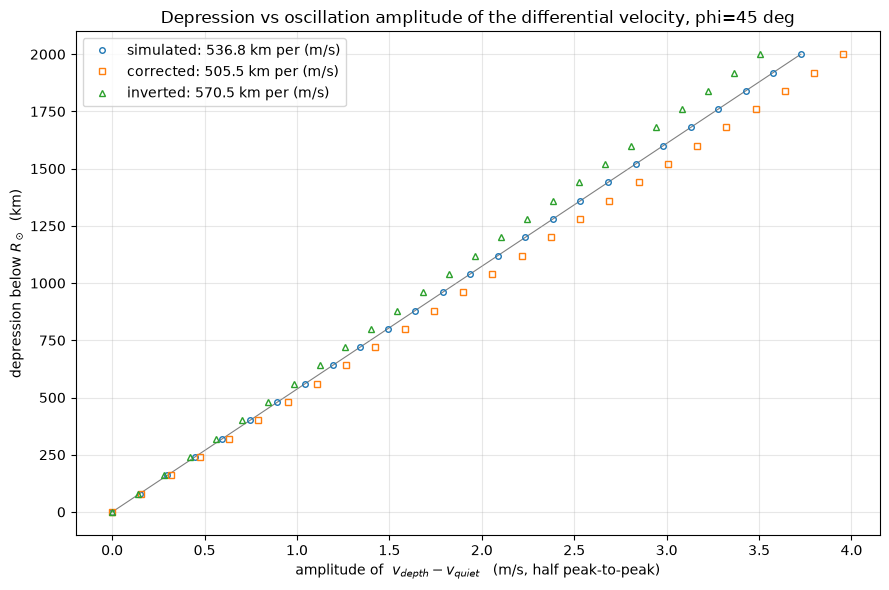

In [24]:
# How deep a depression does a given oscillation amplitude correspond to?
# Sweep the depression, measure the amplitude of (v_depth - v_quiet), and read
# the calibration the other way round: depression as a function of amplitude.

def half_peak_to_peak(x):
    """Oscillation amplitude of the differential velocity over the whole window.

    The estimator matters here: the cubic scales peaks and troughs by different
    factors (0.972 vs 0.909 when inverted at phi=45), so neither the corrected
    nor the inverted difference is a rescaled copy of the simulated one. Half
    peak-to-peak averages the two; a peak-only amplitude halves the bias below.
    """
    return 0.5 * (np.max(x) - np.min(x))


depth_grid = np.linspace(0.0, 2000e3, 26)          # depressions, metres
amp = {name: np.empty_like(depth_grid) for name in TRANSFORMS}

for i, depth in enumerate(depth_grid):
    v_depth = speed_at_depth(phi, t, depth)
    for name, f in TRANSFORMS.items():
        amp[name][i] = half_peak_to_peak(f(v_depth) - quiet[name])

# depression = k * amplitude, fitted through the origin
k = {name: float(a @ depth_grid / (a @ a)) for name, a in amp.items()}

fig, ax = plt.subplots(figsize=(9, 6))
for (name, a), marker in zip(amp.items(), ['o', 's', '^']):
    ax.plot(a, depth_grid / 1e3, marker, ms=4, mfc='none',
            label=f'{name}: {k[name] / 1e3:.1f} km per (m/s)')
ax.plot(amp['simulated'], k['simulated'] * amp['simulated'] / 1e3, lw=0.8, color='gray', zorder=0)
ax.set_xlabel('amplitude of  $v_{depth} - v_{quiet}$   (m/s, half peak-to-peak)')
ax.set_ylabel('depression below $R_\\odot$  (km)')
ax.set_title(f'Depression vs oscillation amplitude of the differential velocity, phi={phi} deg')
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()

out_path = f'/home/thomas/Projects/sun_rotacion_sim/depth_vs_amplitude_phi{phi}.png'
fig.savefig(out_path, dpi=150)
print(f'Saved -> {out_path}')

for name in TRANSFORMS:
    bias = (k[name] - k['simulated']) / k['simulated'] * 100
    print(f'{name:>9}: {1e6 / k[name]:.4f} (m/s) per 1000 km  ->  {k[name] / 1e3:7.2f} km per (m/s)'
          f'   [{bias:+5.1f}% vs simulated]')
print(f'linearity: max |depth - k*amp| = '
      f'{np.abs(depth_grid - k["simulated"] * amp["simulated"]).max():.3f} m over 0..2000 km')

## the hmi.coefficients cubics themselves

In [ ]:
# The 16 cubics themselves, over v = -100 .. 100 m/s.
v_axis = np.linspace(-17000.0, 7000.0, 4001)

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(12, 5))
cmap = plt.get_cmap('viridis')

for i, r in query.iterrows():
    y = np.polyval([r.COEFF3, r.COEFF2, r.COEFF1, r.COEFF0], v_axis)
    color = cmap(i / (len(query) - 1))
    ax0.plot(v_axis, y, lw=1.0, color=color)
    ax1.plot(v_axis, y - r.COEFF0, lw=1.0, color=color)

ax0.set_ylabel('correction  poly(v)  (m/s)')
ax0.set_title('hmi.coefficients cubics, 2017.08.03 + 8 d')
ax1.set_ylabel('poly(v) - COEFF0  (m/s)')
ax1.set_title('same curves with the constant term removed')
for ax in (ax0, ax1):
    ax.set_xlabel('v  (m/s)')
    ax.axvline(0, color='gray', lw=0.5)
    ax.grid(True, alpha=0.3)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(0, (len(query) - 1) * BIN_HOURS))
fig.colorbar(sm, ax=[ax0, ax1], label='hours from the first T_START')

out_path = '/home/thomas/Projects/sun_rotacion_sim/hmi_coefficients_polynomials.png'
fig.savefig(out_path, dpi=150, bbox_inches='tight')
print(f'Saved -> {out_path}')

edges = np.polyval([query.COEFF3, query.COEFF2, query.COEFF1, query.COEFF0], -100.0)
print(f'COEFF0 spread over the 8 days: {query.COEFF0.min():.4f} .. {query.COEFF0.max():.4f} m/s')
row0 = query.loc[0, ['COEFF3', 'COEFF2', 'COEFF1', 'COEFF0']].to_numpy(float)
print(f'poly({v_axis[0]:.0f}) .. poly({v_axis[-1]:.0f}) for row 0: '
      f'{np.polyval(row0, v_axis[0]):.4f} .. {np.polyval(row0, v_axis[-1]):.4f} m/s')
print(f'so across that range each cubic moves by ~{np.ptp(np.polyval(row0, v_axis)):.3f} m/s, '
      f'against a {np.ptp(edges):.3f} m/s spread between windows')

## test: undo the correction on the difference instead

Saved -> /home/thomas/Projects/sun_rotacion_sim/difference_inversion_order_phi45.png
offset  mean(invert(diff) - diff) =  189.852 m/s (mean COEFF0 = 188.802)
amplitude   simulated 2.2356   invert-then-subtract 2.1033 (0.9408x)   subtract-then-invert 3.8564 (1.7250x)
depression read off a 2.236 m/s amplitude: 1200.0 km simulated, 1200.0 km invert-then-subtract, 2200.2 km subtract-then-invert (true 1200 km)


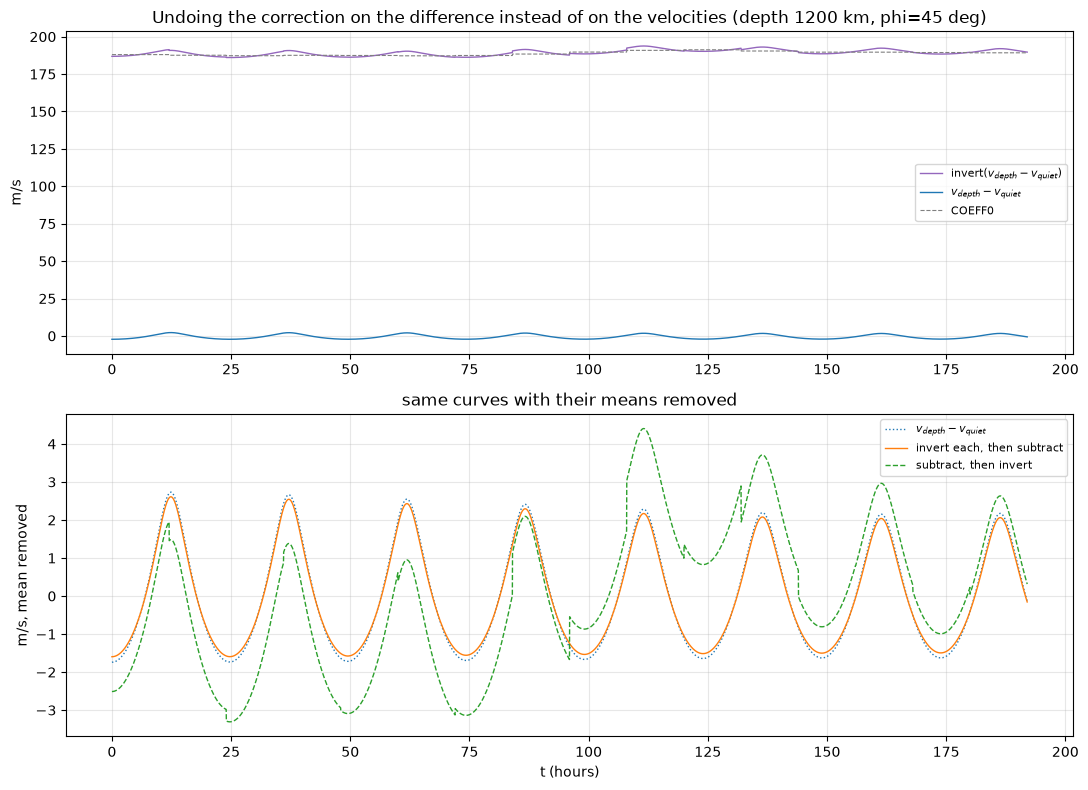

In [31]:
# Does it matter whether the cubic is undone before or after the subtraction?
# invert() is a function of the *absolute* velocity, so it has no reason to
# distribute over a difference -- this cell measures how far off it is.

test_depth = 1200 * 1000
v_depth = speed_at_depth(phi, t, test_depth)

d_sim = v_depth - v_quiet                                   # differential velocity
d_pair = invert_hmi_correction(v_depth, *coeffs) - x_quiet  # invert each, then subtract
d_diff = invert_hmi_correction(d_sim, *coeffs)              # subtract, then invert

fig, (ax0, ax1) = plt.subplots(2, 1, figsize=(11, 8))

ax0.plot(t_hours, d_diff, lw=1.0, color='tab:purple', label='invert($v_{depth} - v_{quiet}$)')
ax0.plot(t_hours, d_sim, lw=1.0, color='tab:blue', label='$v_{depth} - v_{quiet}$')
ax0.plot(t_hours, coeff0, lw=0.8, ls='--', color='gray', label='COEFF0')
ax0.set_ylabel('m/s')
ax0.set_title(f'Undoing the correction on the difference instead of on the velocities '
              f'(depth {test_depth / 1000:.0f} km, phi={phi} deg)')
ax0.legend(fontsize=8)
ax0.grid(True, alpha=0.3)

for label, d, style in [('$v_{depth} - v_{quiet}$', d_sim, ':'),
                        ('invert each, then subtract', d_pair, '-'),
                        ('subtract, then invert', d_diff, '--')]:
    ax1.plot(t_hours, d - d.mean(), lw=1.0, ls=style, label=label)
ax1.set_xlabel('t (hours)')
ax1.set_ylabel('m/s, mean removed')
ax1.set_title('same curves with their means removed')
ax1.legend(fontsize=8)
ax1.grid(True, alpha=0.3)

fig.tight_layout()
out_path = f'/home/thomas/Projects/sun_rotacion_sim/difference_inversion_order_phi{phi}.png'
fig.savefig(out_path, dpi=150)
print(f'Saved -> {out_path}')

amp = lambda d: 0.5 * (np.max(d) - np.min(d))
print(f'offset  mean(invert(diff) - diff) = {np.mean(d_diff - d_sim):8.3f} m/s '
      f'(mean COEFF0 = {coeff0.mean():.3f})')
print(f'amplitude   simulated {amp(d_sim):.4f}   invert-then-subtract {amp(d_pair):.4f} '
      f'({amp(d_pair) / amp(d_sim):.4f}x)   subtract-then-invert {amp(d_diff):.4f} '
      f'({amp(d_diff) / amp(d_sim):.4f}x)')
print(f'depression read off a {amp(d_sim):.3f} m/s amplitude: '
      f'{k["simulated"] * amp(d_sim) / 1e3:.1f} km simulated, '
      f'{k["inverted"] * amp(d_pair) / 1e3:.1f} km invert-then-subtract, '
      f'{k["inverted"] * amp(d_diff) / 1e3:.1f} km subtract-then-invert '
      f'(true {test_depth / 1e3:.0f} km)')

## which reading of hmi.coefficients is right?

Saved -> /home/thomas/Projects/sun_rotacion_sim/reading_A_vs_B_phi45.png

reading A:   -20612.7 ..   -15865.4 m/s   ( 569.7% off the simulated velocity)
reading B:     1960.7 ..     4404.9 m/s   (   3.9% off)

published DATAMEAN spans  -3165.0 ..   2674.5 m/s
poly() over that range spans only  127.0 ..  189.8 m/s
  -> under reading A every published velocity would have to live inside that narrow band. It does not, so reading A is out.
DATAMEAN - OBS_VR =   -5.96 +- 3.87 m/s, while poly(OBS_VR) = +160.65 m/s
  -> the ~160 m/s the cubic predicts has already been taken out of the published product: reading B, and the correction is only a few % of a km/s velocity.


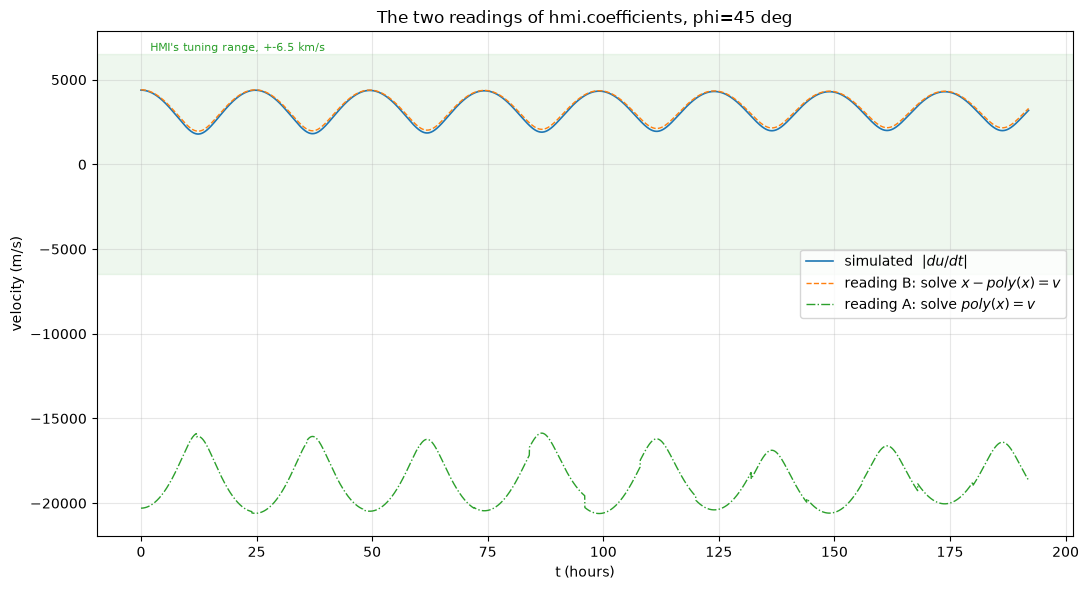

In [34]:
# Which reading of hmi.coefficients is right? There are only two, and they differ
# by an order of magnitude, so it is worth settling against HMI data itself.
#
#   A  the cubic IS the calibration curve:  v_published = poly(v_measured)
#   B  the cubic is a correction:           v_published = v_measured - poly(v_measured)
#
# A is what invert_cubic() does, B is what invert_hmi_correction() does.

x_A = invert_cubic(v_true, *coeffs)             # solve poly(x) = v
x_B = invert_hmi_correction(v_true, *coeffs)    # solve x - poly(x) = v

fig, ax = plt.subplots(figsize=(11, 6))
ax.plot(t_hours, v_true, lw=1.2, label='simulated  $|du/dt|$')
ax.plot(t_hours, x_B, lw=1.0, ls='--', label='reading B: solve $x - poly(x) = v$')
ax.plot(t_hours, x_A, lw=1.0, ls='-.', label='reading A: solve $poly(x) = v$')
ax.axhspan(-6500, 6500, color='tab:green', alpha=0.08)
ax.text(2, 6700, "HMI's tuning range, +-6.5 km/s", fontsize=8, color='tab:green')
ax.set_xlabel('t (hours)')
ax.set_ylabel('velocity (m/s)')
ax.set_title(f'The two readings of hmi.coefficients, phi={phi} deg')
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
out_path = f'/home/thomas/Projects/sun_rotacion_sim/reading_A_vs_B_phi{phi}.png'
fig.savefig(out_path, dpi=150)
print(f'Saved -> {out_path}\n')

print(f'reading A: {x_A.min():10.1f} .. {x_A.max():10.1f} m/s   '
      f'({np.abs(x_A - v_true).max() / np.abs(v_true).max() * 100:6.1f}% off the simulated velocity)')
print(f'reading B: {x_B.min():10.1f} .. {x_B.max():10.1f} m/s   '
      f'({np.abs(x_B - v_true).max() / np.abs(v_true).max() * 100:6.1f}% off)\n')

# --- the deciding evidence: one day of hmi.V_45s, spacecraft velocity vs disk mean
v45 = client.query('hmi.V_45s[2017.08.03_TAI/24h@12m]', key='T_REC,OBS_VR,DATAMEAN')
v45 = v45[np.isfinite(v45.DATAMEAN)]
obs_vr = v45.OBS_VR.to_numpy(dtype=float)
datamean = v45.DATAMEAN.to_numpy(dtype=float)
poly_vr = np.polyval(query.loc[0, ['COEFF3', 'COEFF2', 'COEFF1', 'COEFF0']].to_numpy(float), obs_vr)

print(f'published DATAMEAN spans {datamean.min():8.1f} .. {datamean.max():8.1f} m/s')
print(f'poly() over that range spans only {poly_vr.min():6.1f} .. {poly_vr.max():6.1f} m/s')
print('  -> under reading A every published velocity would have to live inside that '
      'narrow band. It does not, so reading A is out.')
print(f'DATAMEAN - OBS_VR = {np.mean(datamean - obs_vr):+7.2f} +- {np.std(datamean - obs_vr):.2f} m/s, '
      f'while poly(OBS_VR) = {poly_vr.mean():+7.2f} m/s')
print('  -> the ~160 m/s the cubic predicts has already been taken out of the published '
      'product: reading B, and the correction is only a few % of a km/s velocity.')